In [2]:
#Load Dataset

In [3]:
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense
)

C:\Users\Thidar Khaing\.conda\envs\deepenv\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [4]:
#Load Dataset Path

In [12]:
dataset_path = "D:/Deep Learning for Image/dogsHumandb"

img_height = 128
img_width = 128
batch_size = 32

In [7]:
#Split Training, Validation and Testing

In [13]:
# Load training dataset (70%)
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="training",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="binary"
)

# Load temporary validation and testing dataset (30%)
temp_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.30,
    subset="validation",
    seed=123,
    image_size=(img_height, img_width),
    batch_size=batch_size,
    label_mode="binary"
)

# Split 30% into validation (15%) and testing (15%)
temp_batches = tf.data.experimental.cardinality(temp_ds).numpy()

val_batches = temp_batches // 2

val_ds = temp_ds.take(val_batches)
test_ds = temp_ds.skip(val_batches)

print("Classes:", train_ds.class_names)

Found 404 files belonging to 2 classes.
Using 283 files for training.
Found 404 files belonging to 2 classes.
Using 121 files for validation.
Classes: ['dogs', 'human']


In [14]:
#Display sample images

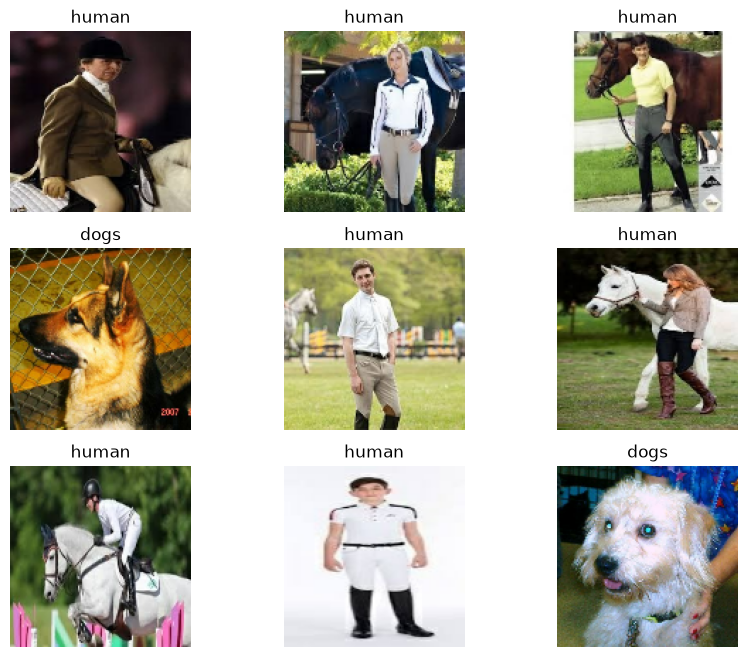

In [15]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label = int(labels[i].numpy()[0])

        plt.title(train_ds.class_names[label])
        plt.axis("off")

plt.show()

## Create a simple CNN model
The CNN architecture contains:
1. Input Layer
2. Convolutional Layer
3. Max Pooling Layer
4. Flatten Layer
5. Fully Connected (Dense) Layer
6. Output Classification Layer

In [18]:
model = Sequential([
    Input(shape=(128, 128, 3)),

    # Convolutional layer
    Conv2D(32, (3, 3), activation='relu'),

    # Max pooling layer
    MaxPooling2D((2, 2)),

    # Flatten layer
    Flatten(),

    # Fully connected layer
    Dense(128, activation='relu'),

    # Output classification layer
    Dense(1, activation='sigmoid')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 127008)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │      16,257,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 16,258,177 (62.02 MB)

 Trainable params: 16,258,177 (62.02 MB)

 Non-trainable params: 0 (0.00 B)

## Compile the Model

In [19]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

## Train the Model

In [20]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

Epoch 1/10


C:\Users\Thidar Khaing\.conda\envs\deepenv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


9/9 ━━━━━━━━━━━━━━━━━━━━ 5s 458ms/step - accuracy: 0.5124 - loss: 2362.5659 - val_accuracy: 0.5938 - val_loss: 170.1642
Epoch 2/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 396ms/step - accuracy: 0.7633 - loss: 94.3924 - val_accuracy: 0.5312 - val_loss: 239.1038
Epoch 3/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 358ms/step - accuracy: 0.7739 - loss: 56.2365 - val_accuracy: 0.8125 - val_loss: 47.5614
Epoch 4/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 370ms/step - accuracy: 0.9187 - loss: 9.0456 - val_accuracy: 0.6719 - val_loss: 62.6405
Epoch 5/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 366ms/step - accuracy: 0.9682 - loss: 3.5520 - val_accuracy: 0.8438 - val_loss: 33.4135
Epoch 6/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 348ms/step - accuracy: 0.9647 - loss: 2.3303 - val_accuracy: 0.8438 - val_loss: 31.3229
Epoch 7/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 352ms/step - accuracy: 0.9717 - loss: 1.6731 - val_accuracy: 0.7812 - val_loss: 33.6594
Epoch 8/10
9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 348ms/step - accuracy: 0.9929 - loss: 0.5500 - val_accuracy: 0.7969 - val_lo

## Test the Model

In [21]:
test_loss, test_accuracy = model.evaluate(test_ds)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.7719 - loss: 54.8092 
Test Loss: 54.809200286865234
Test Accuracy: 77.19298005104065 %


## Plot the Training Accuracy and Loss

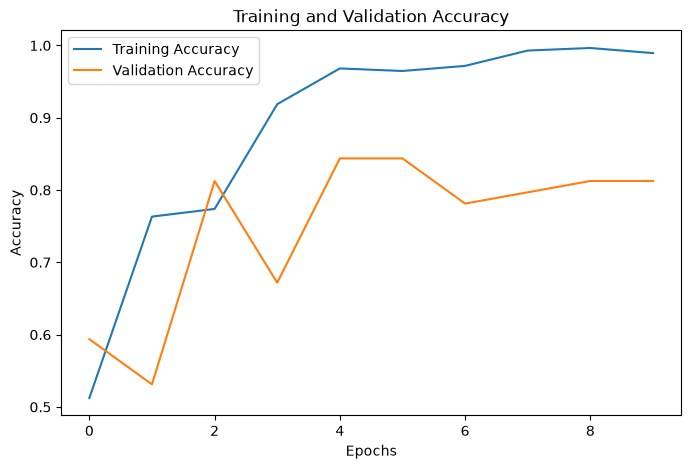

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'],
         label='Training Accuracy')

plt.plot(history.history['val_accuracy'],
         label='Validation Accuracy')

plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [23]:
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

In [25]:
import numpy as np
# Get actual labels and predicted labels
y_true = []
y_pred = []

for images, labels in test_ds:

    # Actual labels
    y_true.extend(labels.numpy().flatten())

    # Model predictions
    predictions = model.predict(images, verbose=0)

    # Convert probabilities into class labels
    predicted_labels = (predictions >= 0.5).astype(int)

    y_pred.extend(predicted_labels.flatten())

# Convert to NumPy arrays
y_true = np.array(y_true).astype(int)
y_pred = np.array(y_pred).astype(int)

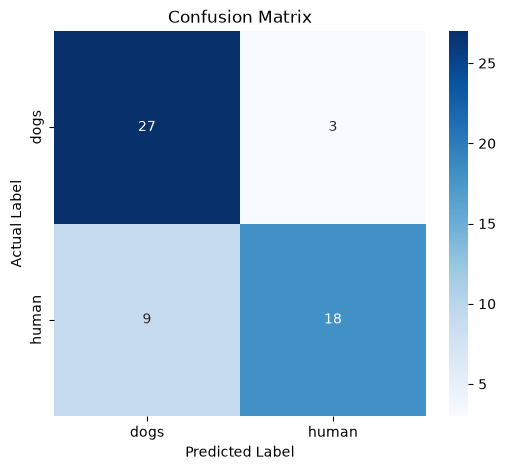

In [26]:
# Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Display confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=train_ds.class_names,
    yticklabels=train_ds.class_names
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.show()

In [28]:
from sklearn.metrics import confusion_matrix

class_names = train_ds.class_names

print("Per-Class Accuracy:")

for i, class_name in enumerate(class_names):

    # One-vs-Rest confusion matrix
    TP = np.sum((y_true == i) & (y_pred == i))
    TN = np.sum((y_true != i) & (y_pred != i))
    FP = np.sum((y_true != i) & (y_pred == i))
    FN = np.sum((y_true == i) & (y_pred != i))

    accuracy = (TP + TN) / (TP + TN + FP + FN)

    print(f"{class_name}: {accuracy * 100:.2f}%")

Per-Class Accuracy:
dogs: 78.95%
human: 78.95%


In [29]:
from sklearn.metrics import (
    precision_recall_fscore_support,
    confusion_matrix
)

class_names = train_ds.class_names

# Calculate precision, recall and F1-score
precision, recall, f1, support = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=[0, 1],
    zero_division=0
)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

# Calculate per-class accuracy
class_accuracy = []

for i in range(len(class_names)):

    TP = cm[i, i]
    FN = np.sum(cm[i, :]) - TP
    FP = np.sum(cm[:, i]) - TP
    TN = np.sum(cm) - TP - FN - FP

    acc = (TP + TN) / np.sum(cm)

    class_accuracy.append(acc)

print("\nPerformance Evaluation")
print("-" * 85)
print(f"{'Class':<12}{'Accuracy':>12}{'Precision':>12}"
      f"{'Recall':>12}{'F1-score':>12}")

for i, name in enumerate(class_names):

    print(
        f"{name:<12}"
        f"{class_accuracy[i]*100:>11.2f}%"
        f"{precision[i]*100:>11.2f}%"
        f"{recall[i]*100:>11.2f}%"
        f"{f1[i]*100:>11.2f}%"
    )


Performance Evaluation
-------------------------------------------------------------------------------------
Class           Accuracy   Precision      Recall    F1-score
dogs              78.95%      75.00%      90.00%      81.82%
human             78.95%      85.71%      66.67%      75.00%


In [30]:
overall_accuracy = accuracy_score(y_true, y_pred)

print("Overall Accuracy:",
      f"{overall_accuracy * 100:.2f}%")

Overall Accuracy: 78.95%


In [32]:
from tensorflow.keras.utils import load_img, img_to_array

image_path = "D:/Deep Learning for Image/Test_Images/Test.jpg"

img = load_img(
    image_path,
    target_size=(128, 128)
)

img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

# Predict
prediction = model.predict(img_array)

if prediction[0][0] >= 0.5:
    print("Prediction: Dog")
else:
    print("Prediction: Cat")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
Prediction: Dog


In [36]:
model.save("D:/Deep Learning for Image/models/dog_human_cnn_model.keras")

In [38]:
from tensorflow.keras.models import load_model
loadModel = load_model("D:/Deep Learning for Image/models/dog_human_cnn_model.keras")
#loadModel.summary()

In [39]:
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

image_path = "D:/Deep Learning for Image/Test_Images/Test.jpg"

img = load_img(
    image_path,
    target_size=(128, 128)
)

img_array = img_to_array(img)
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array)

if prediction[0][0] >= 0.5:
    print("Predicted Class: Dog")
else:
    print("Predicted Class: Human")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
Predicted Class: Dog
